# OTS 降水订正

`OtsForecastPlugin` 把格点场按半径 0.7° 反距离插值，再按阈值表做分段线性订正。

ECMWF 文件名里的起报是世界时。起报 2026052300、时效 060 小时，有效时刻是世界时 2026052512，加 8 小时后是北京时 2026052520。实况文件按北京时命名，对应 `26052520.000`。

这一次的 24 小时降水主体在黄淮，约 26–40°N、108–124°E。福建业务网格在雨区南侧，只看福建时预报和实况都只剩边缘，落区对不上。下面三张图用同一片雨区。

## 参数

| 参数 | 本示例 | 含义 |
| --- | --- | --- |
| 输入场 | ECMWF `2026052300.060.m4` | 起报 2026052300 世界时，预报时效 060 小时 |
| 有效时刻 | 世界时 2026052512 | 起报加 60 小时 |
| 实况 | `26052520.000` | 北京时 2026052520，与上面的有效时刻是同一时刻 |
| 图的范围 | 26–40°N，108–124°E，0.1° | 这一次降水所在的区域 |
| `interpolation_radius` | 0.7 | 反距离插值半径，单位度 |
| 阈值表 | 时效 060 那一行 | 来自已有的 `fjyz.txt` |


预报起报 2026052300 世界时  时效 060h
有效时刻 2026052512 世界时  =  2026052520 北京时
实况文件 26052520.000 站点数 1137 最大 253.8 mm
订正最大 173.5 mm


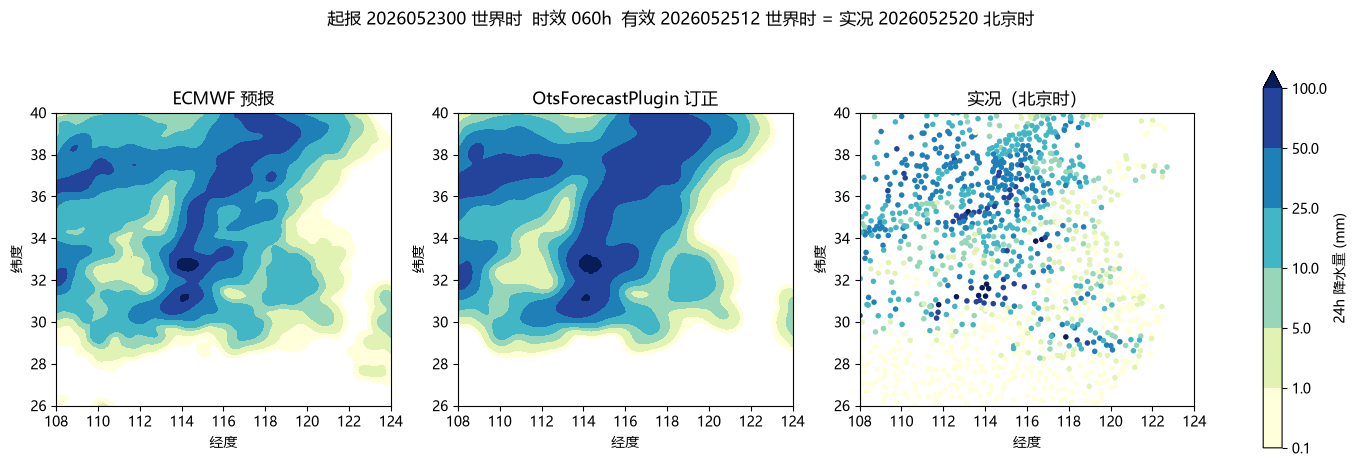

In [1]:
import contextlib
import io
import sys
from datetime import datetime, timedelta
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from matplotlib import font_manager
from matplotlib.colors import BoundaryNorm

PKG = Path(r"d:\Work\NIMM_pip_repos\00temp\ots_fzmos_rain")
for path in (PKG, PKG / "src"):
    if str(path) not in sys.path:
        sys.path.insert(0, str(path))

with contextlib.redirect_stdout(io.StringIO()):
    import meteva_base as meb

from _util_plugin import LEAD_HOURS
from ots_fzmos_rain_plugin import OtsForecastPlugin
from utils.grid import GridConfig
from utils.ots_io import read_thresholds

DATA_DIR = Path(r"D:\data1\zhongzhuan\nimm_test_data\multi_rain_mait24_blending\test_data")
ECMWF = DATA_DIR / "ecmwf" / "sfc" / "20260523" / "2026052300.060.m4"
FJYZ = Path(r"d:\Work\NIMM_pip_repos\00temp\autofjyz_10_12_py_v2\result\fjyz.txt")
INITIAL_UTC = datetime(2026, 5, 23, 0)
LEAD = 60
LEVELS = [0.1, 1, 5, 10, 25, 50, 100]
NORM = BoundaryNorm(LEVELS, ncolors=256, extend="max")
# 降水主体在黄淮，不在福建业务网格里。
LAT0, LAT1 = 26.0, 40.0
LON0, LON1 = 108.0, 124.0
DL = 0.1
OUTPUT = GridConfig(
    lat_start=LAT0,
    lon_start=LON0,
    lat_end=LAT1,
    lon_end=LON1,
    dlat=DL,
    dlon=DL,
    num_x=int(round((LON1 - LON0) / DL)) + 1,
    num_y=int(round((LAT1 - LAT0) / DL)) + 1,
)

font = Path(r"C:\Windows\Fonts\msyh.ttc")
if font.is_file():
    font_manager.fontManager.addfont(str(font))
    plt.rcParams["font.sans-serif"] = ["Microsoft YaHei"]
plt.rcParams["axes.unicode_minus"] = False


def read_micaps3_rain(path):
    encoding, _ = meb.io.get_encoding_of_file(str(path), read_rows=1)
    strs = []
    skip_num = 0
    nline = 0
    with open(path, "r", encoding=encoding) as file:
        while True:
            skip_num += 1
            strs.extend(file.readline().split())
            if len(strs) > 8:
                nline = int(float(strs[8]))
            if len(strs) > 11 + nline:
                nregion = int(float(strs[11 + nline]))
                if len(strs) == nline + 2 * nregion + 14:
                    break
    sta = pd.read_csv(
        path, skiprows=skip_num, sep=r"\s+", header=None, usecols=[0, 1, 2, 4], encoding=encoding,
    )
    sta.columns = ["id", "lon", "lat", "data0"]
    return sta[sta["data0"] < 9990]


with contextlib.redirect_stdout(io.StringIO()):
    grd = meb.read_griddata_from_micaps4(str(ECMWF))
values = np.squeeze(np.asarray(grd.values, dtype=np.float32))
lat = np.asarray(grd.lat.values, dtype=float)
lon = np.asarray(grd.lon.values, dtype=float)
source_grid = GridConfig(
    lat_start=float(lat[0]),
    lon_start=float(lon[0]),
    lat_end=float(lat[-1]),
    lon_end=float(lon[-1]),
    dlat=float(lat[1] - lat[0]),
    dlon=float(lon[1] - lon[0]),
    num_x=int(lon.size),
    num_y=int(lat.size),
)
thresholds = read_thresholds(FJYZ)
lead_index = LEAD_HOURS.index(LEAD)
fields = [np.full(values.shape, np.float32(9999.0)) for _ in LEAD_HOURS]
fields[lead_index] = values
rain12, _rain24 = OtsForecastPlugin().process(
    fields,
    [source_grid] * len(LEAD_HOURS),
    OUTPUT,
    0.7,
    thresholds,
    pro_count=1,
)
corrected = np.asarray(rain12[lead_index], dtype=np.float32)

valid_utc = INITIAL_UTC + timedelta(hours=LEAD)
valid_bjt = valid_utc + timedelta(hours=8)
ob_path = DATA_DIR / "Observation" / "r24" / "sfc" / ("%s.000" % valid_bjt.strftime("%y%m%d%H"))
ob = read_micaps3_rain(ob_path)
in_box = (ob["lat"] >= LAT0) & (ob["lat"] <= LAT1) & (ob["lon"] >= LON0) & (ob["lon"] <= LON1)
ob_box = ob.loc[in_box]
print("预报起报 %s 世界时  时效 %03dh" % (INITIAL_UTC.strftime("%Y%m%d%H"), LEAD))
print("有效时刻 %s 世界时  =  %s 北京时" % (valid_utc.strftime("%Y%m%d%H"), valid_bjt.strftime("%Y%m%d%H")))
print("实况文件", ob_path.name, "站点数", len(ob_box), "最大 %.1f mm" % float(ob_box["data0"].max()))
print("订正最大 %.1f mm" % float(np.nanmax(corrected[corrected < 2000])))


def axis(start, step, count):
    return float(start) + np.arange(count) * float(step)


lat_in = (lat >= LAT0) & (lat <= LAT1)
lon_in = (lon >= LON0) & (lon <= LON1)
src_show = values.astype(float)[np.ix_(lat_in, lon_in)]
src_show[src_show >= 2000] = np.nan
out_show = corrected.astype(float)
out_show[out_show >= 2000] = np.nan
out_lat = axis(OUTPUT.lat_start, OUTPUT.dlat, OUTPUT.num_y)
out_lon = axis(OUTPUT.lon_start, OUTPUT.dlon, OUTPUT.num_x)

fig, axes = plt.subplots(1, 3, figsize=(13.5, 4.8), constrained_layout=True)
mesh = axes[0].contourf(
    lon[lon_in], lat[lat_in], np.clip(src_show, 0, None),
    levels=LEVELS, cmap="YlGnBu", norm=NORM, extend="max",
)
axes[0].set_title("ECMWF 预报")
mesh = axes[1].contourf(
    out_lon, out_lat, np.clip(out_show, 0, None),
    levels=LEVELS, cmap="YlGnBu", norm=NORM, extend="max",
)
axes[1].set_title("OtsForecastPlugin 订正")
axes[2].scatter(
    ob_box["lon"], ob_box["lat"], c=ob_box["data0"], s=16,
    cmap="YlGnBu", norm=NORM, linewidths=0,
)
axes[2].set_xlim(LON0, LON1)
axes[2].set_ylim(LAT0, LAT1)
axes[2].set_title("实况（北京时）")
for ax in axes:
    ax.set_xlabel("经度")
    ax.set_ylabel("纬度")
    ax.set_aspect("equal", adjustable="box")
fig.colorbar(mesh, ax=axes, shrink=0.85, label="24h 降水量 (mm)")
fig.suptitle(
    "起报 %s 世界时  时效 %03dh  有效 %s 世界时 = 实况 %s 北京时"
    % (INITIAL_UTC.strftime("%Y%m%d%H"), LEAD, valid_utc.strftime("%Y%m%d%H"), valid_bjt.strftime("%Y%m%d%H"))
)
plt.show()
